# E. coli datasets in torchcell

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Mjvolk3/torchcell/blob/main/experiments/034-showcase-datasets/notebooks/ecoli_datasets.ipynb)

Four built *Escherichia coli* K-12 datasets, loaded from the public `tc-data` endpoint. The cells that load and read the data are the interface to copy. The plotting cells are collapsed: expand one to see how its figure is drawn. To run it with nothing installed, open it in Google Colab with the badge above and choose Runtime, Run all: the first cell installs `torchcell`. On your own machine, run the cells top to bottom in an empty directory with `torchcell` installed (Python 3.13 or newer). The stores download into `./data/torchcell/` and the figures are written to `./figures/`.

## Install

One line installs torchcell and everything the loaders need. On your own machine `pip install torchcell` is the same thing.

In [1]:
%pip install -q --no-warn-conflicts torchcell

## Setup

Setting `TC_DATA_URL` makes each loader download its built store. `show` prints one part of a record as indented JSON.

In [2]:
import hashlib
import json
import os
from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd

from torchcell.datasets.artifact import content_sha256
from torchcell.datasets.client import DatasetClient
from torchcell.datasets.ecoli.babu2014 import GeneInteractionBabu2014Dataset
from torchcell.datasets.ecoli.campos2018 import (
    FEATURE_UNITS,
    MORPHOLOGY_ASSAY,
    GrowthRateCampos2018Dataset,
    MorphologyCampos2018Dataset,
)
from torchcell.datasets.ecoli.fuhrer2017 import MetabolomeFuhrer2017Dataset
from torchcell.endpoint_http import DEFAULT_URL

# A loader downloads its built store only when TC_DATA_URL is set. Without it the loader
# builds the store from the publisher's files, which is the developer path.
os.environ.setdefault("TC_DATA_URL", DEFAULT_URL)

DATA = Path("data/torchcell")  # each dataset unpacks into DATA/<slug>/
pd.set_option("display.precision", 4)


def brief(value: Any, depth: int = 1) -> Any:
    """A record part with anything nested deeper than ``depth`` replaced by its size."""
    if isinstance(value, dict):
        kept = {k: v for k, v in value.items() if k != "provenance_gaps"}
        if depth < 0:
            return f"<{len(kept)} fields>"
        return {k: brief(v, depth - 1) for k, v in kept.items()}
    if isinstance(value, list):
        return f"<{len(value)} items>" if value else []
    return getattr(value, "value", value)  # an enum member prints as its value


def show(part: dict[str, Any]) -> None:
    """Print one part of a record as indented JSON, two levels deep."""
    print(json.dumps(brief(part), indent=2, default=str))

Figure style (collapsed): one row of three panels, red below and blue above a reference level.

In [3]:
import matplotlib.pyplot as plt
from matplotlib.figure import Figure

from torchcell.utils import (
    PANEL_WIDTHS_MM,
    PLOT_PALETTE,
    mm_to_in,
    panel_label,
)

ORANGE, RED, PURPLE, YELLOW, BLUE, GRAY = PLOT_PALETTE[:6]
NEGATIVE, POSITIVE = RED, BLUE  # below and above a reference level, in every figure
plt.rcParams.update(
    {
        "font.family": ["Arial", "DejaVu Sans"],
        "font.size": 7,
        "axes.labelsize": 7,
        "axes.titlesize": 7,
        "xtick.labelsize": 7,
        "ytick.labelsize": 7,
        "legend.fontsize": 7,
        "axes.linewidth": 0.5,
        "xtick.major.width": 0.5,
        "ytick.major.width": 0.5,
        "legend.frameon": False,
        "figure.dpi": 150,  # size of a figure shown in a notebook
        "svg.fonttype": "none",  # text stays text in the SVG
        "svg.hashsalt": "torchcell",  # the same bytes on every run
    }
)
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)


def three_panels() -> tuple[Figure, Any]:
    """One row of three panels, 179 mm wide."""
    return plt.subplots(
        1,
        3,
        figsize=(mm_to_in(PANEL_WIDTHS_MM["full"]), mm_to_in(54)),
        layout="constrained",
    )


def save(figure: Figure, name: str) -> None:
    """Letter the panels a to c and write figures/<name>.svg and .png."""
    for axis, letter in zip(figure.axes, "abc", strict=True):
        panel_label(axis, letter)
    figure.savefig(FIGURES / f"{name}.svg", metadata={"Date": None})
    figure.savefig(FIGURES / f"{name}.png", dpi=200)

## What the endpoint serves

In [4]:
client = DatasetClient.from_env()
print("endpoint", client.url)
SLUGS = (
    "ecoli_growth_rate_campos2018",
    "ecoli_morphology_campos2018",
    "gene_interaction_babu2014",
    "metabolome_fuhrer2017",
)
for slug in SLUGS:
    artifact = client.select(slug)  # newest archive the installed major.minor reads
    if artifact is None:
        raise SystemExit(f"{client.url} serves no {slug} archive this torchcell reads")
    print(slug)
    print(f"  loader   {artifact.dataset_class}")
    print(f"  archive  {artifact.archive}  ({artifact.archive_bytes:,} bytes)")
    print(f"  records  {artifact.n_experiments:,}")
    print(f"  release  knowledge graph {artifact.kg_version} ({artifact.kg_release})")

endpoint http://torchcell-database.ncsa.illinois.edu:8724
ecoli_growth_rate_campos2018
  loader   GrowthRateCampos2018Dataset
  archive  ecoli_growth_rate_campos2018-1.8.4-ef455265.tar.xz  (144,152 bytes)
  records  3,664
  release  knowledge graph 4.0 (2026.10.17-4295f7ca)
ecoli_morphology_campos2018
  loader   MorphologyCampos2018Dataset
  archive  ecoli_morphology_campos2018-1.8.4-52643bef.tar.xz  (856,456 bytes)
  records  3,664
  release  knowledge graph 4.0 (2026.10.17-4295f7ca)
gene_interaction_babu2014
  loader   GeneInteractionBabu2014Dataset
  archive  gene_interaction_babu2014-1.8.4-412a73ed.tar.xz  (1,049,192 bytes)
  records  42,705
  release  knowledge graph 4.0 (2026.10.17-4295f7ca)
metabolome_fuhrer2017
  loader   MetabolomeFuhrer2017Dataset
  archive  metabolome_fuhrer2017-1.8.4-7eb33983.tar.xz  (81,780,576 bytes)
  records  3,806
  release  knowledge graph 4.0 (2026.10.17-4295f7ca)


## Growth rate (Campos 2018)

One record per Keio strain. The label is the maximal growth rate relative to the parent strain BW25113.

In [5]:
growth = GrowthRateCampos2018Dataset(root=str(DATA / "ecoli_growth_rate_campos2018"))
print(f"{len(growth):,} records")

3,664 records


A record is a dict with three keys: `experiment` (genotype, environment, phenotype), `reference` and `publication`.

In [6]:
record = growth[0]  # a dict with three keys: experiment, reference, publication
experiment = record["experiment"]
show(experiment["genotype"]["perturbations"][0])
show(experiment["environment"])
show(experiment["phenotype"])
print("reference fitness", record["reference"]["phenotype_reference"]["fitness"])
print("source", record["publication"]["doi_url"])

{
  "systematic_gene_name": "BW25113_1967",
  "perturbed_gene_name": "hchA",
  "gene_namespace": "ecoli_k12_bw25113_locus_tag",
  "identifier_mapping": {
    "source_identifier": "hchA",
    "route": "gene_symbol"
  },
  "provenance": "engineered",
  "state": "absent",
  "mechanism_so_id": "SO:0000159",
  "mechanism_so_name": "deletion",
  "description": "Gene deletion strain, with its collection, cassette and construction as stated",
  "perturbation_type": "deletion_strain",
  "deletion_type": "strain",
  "collection": "Keio collection",
  "cassette": "kanamycin-resistance cassette",
  "construction": {
    "strain_accession": null,
    "lab": null,
    "batch": null,
    "plate": "1",
    "well": "A001"
  }
}
{
  "media": {
    "name": "M9 with 0.1% (w/v) casamino acids and 0.2% (w/v) glucose (Campos 2018)",
    "state": "liquid",
    "is_synthetic": false,
    "base_medium": "M9",
    "components": "<6 items>",
    "dropouts": [],
    "provenance": "<1 items>"
  },
  "temperature": 

All records as a table.

In [7]:
rows = []
for r in (growth[i] for i in range(len(growth))):
    deletion = r["experiment"]["genotype"]["perturbations"][0]
    rows.append(
        {
            "gene": deletion["perturbed_gene_name"],
            "locus_tag": deletion["systematic_gene_name"],
            "plate": int(deletion["construction"]["plate"]),
            "fitness": r["experiment"]["phenotype"]["fitness"],
        }
    )
growth_table = pd.DataFrame(rows)
print(
    "fitness min {:.4f}  median {:.4f}  max {:.4f}".format(
        growth_table["fitness"].min(),
        growth_table["fitness"].median(),
        growth_table["fitness"].max(),
    )
)
growth_table.head(6)

fitness min 0.1218  median 1.0042  max 1.3514


,gene,locus_tag,plate,fitness
0,hchA,BW25113_1967,1,1.0201
1,bglG,BW25113_3723,1,1.1317
2,cytR,BW25113_3934,1,0.8306
3,fnr,BW25113_1334,1,0.9604
4,hupB,BW25113_0440,1,1.0240
5,nagC,BW25113_0676,1,0.9816


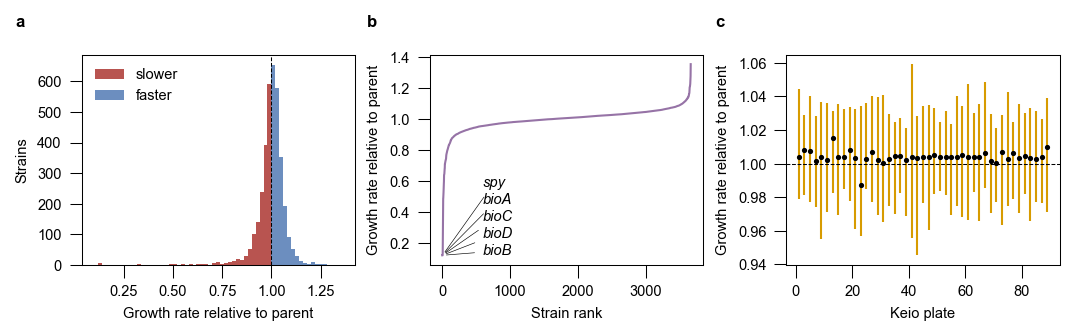

In [8]:
figure, (left, middle, right) = three_panels()
edges = np.arange(0.10, 1.38, 0.02)
slower = growth_table["fitness"] < 1.0
left.hist(
    growth_table.loc[slower, "fitness"], bins=edges, color=NEGATIVE, label="slower"
)
left.hist(
    growth_table.loc[~slower, "fitness"], bins=edges, color=POSITIVE, label="faster"
)
left.axvline(1.0, color="black", linewidth=0.5, linestyle="--")
left.set(xlabel="Growth rate relative to parent", ylabel="Strains")
left.legend()

ranked = growth_table.sort_values("fitness").reset_index(drop=True)
middle.plot(ranked.index + 1, ranked["fitness"], color=PURPLE, linewidth=1)
for rank, row in ranked.head(5).iterrows():
    middle.annotate(
        row["gene"],
        (rank + 1, row["fitness"]),
        xytext=(600, 0.15 + 0.11 * rank),
        fontstyle="italic",
        va="center",
        arrowprops={"arrowstyle": "-", "linewidth": 0.3},
    )
middle.set(xlabel="Strain rank", ylabel="Growth rate relative to parent")

plates = growth_table.groupby("plate")["fitness"].quantile([0.25, 0.5, 0.75]).unstack()
right.vlines(plates.index, plates[0.25], plates[0.75], color=ORANGE, linewidth=1)
right.plot(plates.index, plates[0.5], "o", color="black", markersize=1.5)
right.axhline(1.0, color="black", linewidth=0.5, linestyle="--")
right.set(xlabel="Keio plate", ylabel="Growth rate relative to parent")
save(figure, "ecoli_growth_rate_campos2018")

### The same record as typed objects

`transform_item` validates a record through the pydantic classes of the schema.

In [9]:
typed = growth.transform_item(record)  # the same record as validated pydantic objects
experiment = typed["experiment"]
print(type(experiment).__name__, type(experiment.phenotype).__name__)
print(
    experiment.genotype.perturbations[0].perturbed_gene_name,
    experiment.phenotype.fitness,
)

FitnessExperiment FitnessPhenotype
hchA 1.0201256910920211


## Cell shape and cell cycle (Campos 2018)

The same strains from the same imaging screen, with cell-shape means and cell-cycle features.

In [10]:
morphology = MorphologyCampos2018Dataset(root=str(DATA / "ecoli_morphology_campos2018"))
print(f"{len(morphology):,} records")
show(morphology[0]["experiment"]["phenotype"])

3,664 records
{
  "graph_level": "global",
  "label_name": "morphology",
  "label_statistic_name": "morphology_coefficient_of_variation",
  "assay": "campos2018",
  "morphology": {
    "<L>": 3.19546621533025,
    "<W>": 1.17312345844031,
    "<A>": 3.23402304903965,
    "<V>": 2.73935580483487,
    "<SA>": 11.4016813687147,
    "<P>": 7.58374863028241,
    "<C>": 0.720139126605895,
    "<Ar>": 0.38481367194436,
    "<SA/V>": 4.20669389106828,
    "<NA>": 1.58381392077006,
    "rho_CD": 0.175309454457351,
    "CDN_C0": 0.686654877888511,
    "Rel.timing div": 0.646839306013814,
    "Rel.timing nuc": 0.578074023057654,
    "%2N": 0.331474592957771
  },
  "morphology_coefficient_of_variation": {
    "CV_L": 0.236850387516941,
    "CV_W": 0.0481438146291384,
    "CV_A": 0.260557043912679,
    "CV_V": 0.271618792599827,
    "CV_SA": 0.238477391654462,
    "CV_P": 0.206559266634767,
    "CV_C": 0.143766140830845,
    "CV_Ar": 0.247848604834858,
    "CV_SA/V": 0.0904532214293887,
    "CV_DR"

Means (`<...>`) go to `morphology` and coefficients of variation (`CV_...`) to `morphology_coefficient_of_variation`. The nucleoid and cell-cycle features exist only for strains imaged with a nucleoid channel.

In [11]:
# The assay vocabulary names every feature a record can hold, with its unit.
features = pd.DataFrame(
    feature.model_dump(mode="json") for feature in MORPHOLOGY_ASSAY.features
).drop(columns="note")
print(features.to_string(index=False))
features

        symbol                                                                name         group                statistic unit
           <L>                                                    Mean cell length morphological                     mean   µm
          CV_L                                             Cell length variability morphological coefficient_of_variation None
           <W>                                                     Mean cell width morphological                     mean   µm
          CV_W                                              Cell width variability morphological coefficient_of_variation None
           <A>                                                      Mean cell area morphological                     mean  µm2
          CV_A                                               Cell area variability morphological coefficient_of_variation None
           <V>                                                    Mean cell volume morphological               

,symbol,name,group,statistic,unit
0,<L>,Mean cell length,morphological,mean,µm
1,CV_L,Cell length variability,morphological,coefficient_of_variation,None
2,<W>,Mean cell width,morphological,mean,µm
3,CV_W,Cell width variability,morphological,coefficient_of_variation,None
4,<A>,Mean cell area,morphological,mean,µm2
5,CV_A,Cell area variability,morphological,coefficient_of_variation,None
6,<V>,Mean cell volume,morphological,mean,µm3
7,CV_V,Cell volume variability,morphological,coefficient_of_variation,None
8,<SA>,Mean cell surface area,morphological,mean,µm2
9,CV_SA,Cell surface area variability,morphological,coefficient_of_variation,None


In [12]:
morphology_table = pd.DataFrame(
    {
        "gene": r["experiment"]["genotype"]["perturbations"][0]["perturbed_gene_name"],
        **r["experiment"]["phenotype"]["morphology"],
    }
    for r in (morphology[i] for i in range(len(morphology)))
).set_index("gene")
unit = FEATURE_UNITS.value  # feature symbol -> unit, as the release states it
print("table shape   ", morphology_table.shape)
print(
    "features per strain:",
    morphology_table.notna().sum(axis=1).value_counts().to_dict(),
)
print("units         ", {symbol: unit[symbol] for symbol in ("<L>", "<W>", "<A>")})
morphology_table.head(6)

table shape    (3664, 15)
features per strain: {15: 3422, 9: 242}
units          {'<L>': 'µm', '<W>': 'µm', '<A>': 'µm2'}


,<L>,<W>,<A>,<V>,<SA>,<P>,<C>,<Ar>,<SA/V>,<NA>,rho_CD,CDN_C0,Rel.timing div,Rel.timing nuc,%2N
gene,,,,,,,,,,,,,,,
hchA,3.1955,1.1731,3.2340,2.7394,11.4017,7.5837,0.7201,0.3848,4.2067,1.5838,0.1753,0.6867,0.6468,0.5781,0.3315
bglG,3.1495,1.1772,3.1965,2.7158,11.2757,7.4770,0.7325,0.3897,4.1760,1.5272,0.4017,0.5812,0.7282,0.6562,0.2691
cytR,3.1203,1.2074,3.2240,2.7960,11.4182,7.4732,0.7420,0.4045,4.1018,1.5670,0.5403,0.5501,0.6898,0.6252,0.2903
fnr,3.1126,1.1413,3.0587,2.5081,10.6631,7.3717,0.7219,0.3790,4.2452,1.5483,0.5705,0.4603,0.6780,0.6117,0.3047
hupB,3.3444,1.0857,3.1668,2.4884,10.9452,7.7780,0.6767,0.3411,4.3908,1.4430,0.5330,0.5900,0.7660,0.7256,0.2058
nagC,3.1478,1.1609,3.1520,2.6341,11.0576,7.4745,0.7244,0.3834,4.2069,1.5803,0.7041,0.5140,0.6832,0.6237,0.2982


The growth-rate dataset holds the same strains in the same order.

In [13]:
# The two Campos 2018 datasets hold the same strains in the same order, so the growth
# rate of each strain sits beside its cell shape.
assert list(morphology_table.index) == list(growth_table["gene"])
shape_growth = morphology_table.assign(fitness=growth_table["fitness"].to_numpy())
rank_correlation = shape_growth["<A>"].rank().corr(shape_growth["fitness"].rank())
print(f"strains {len(shape_growth):,}")
print(f"Spearman correlation of cell area with growth rate {rank_correlation:.3f}")

strains 3,664
Spearman correlation of cell area with growth rate 0.095


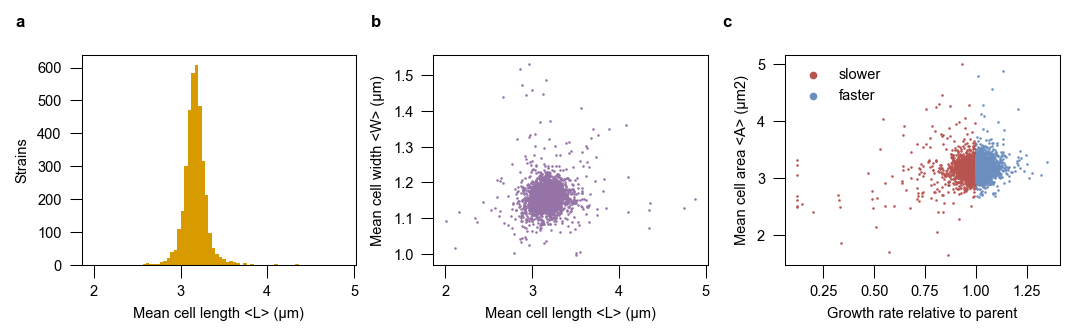

In [14]:
figure, (left, middle, right) = three_panels()
left.hist(morphology_table["<L>"], bins=np.arange(2.0, 4.92, 0.04), color=ORANGE)
left.set(xlabel=f"Mean cell length <L> ({unit['<L>']})", ylabel="Strains")

middle.scatter(
    morphology_table["<L>"],
    morphology_table["<W>"],
    s=1.5,
    color=PURPLE,
    linewidths=0,
    rasterized=True,
)
middle.set(
    xlabel=f"Mean cell length <L> ({unit['<L>']})",
    ylabel=f"Mean cell width <W> ({unit['<W>']})",
)

slower = shape_growth["fitness"] < 1.0
for mask, color, label in ((slower, NEGATIVE, "slower"), (~slower, POSITIVE, "faster")):
    right.scatter(
        shape_growth.loc[mask, "fitness"],
        shape_growth.loc[mask, "<A>"],
        s=1.5,
        color=color,
        linewidths=0,
        rasterized=True,
        label=label,
    )
right.set(
    xlabel="Growth rate relative to parent",
    ylabel=f"Mean cell area <A> ({unit['<A>']})",
)
right.legend(markerscale=3)
save(figure, "ecoli_morphology_campos2018")

## Genetic interactions (Babu 2014)

One record per double mutant of the released high-confidence set. The label is the pair's S-score.

In [15]:
interaction = GeneInteractionBabu2014Dataset(
    root=str(DATA / "gene_interaction_babu2014")
)
print(f"{len(interaction):,} records")
record = interaction[0]
for perturbation in record["experiment"]["genotype"]["perturbations"]:
    print(
        perturbation["perturbed_gene_name"],
        perturbation["systematic_gene_name"],
        "|",
        perturbation["collection"],
    )
show(record["experiment"]["phenotype"])

42,705 records
thrA b0002 | Hfr Cavalli (Hfr C) donor query strains
dnaJ b0015 | Keio collection
{
  "graph_level": "hyperedge",
  "label_name": "gene_interaction",
  "label_statistic_name": "gene_interaction_p_value",
  "gene_interaction": -4.43348,
  "gene_interaction_p_value": null,
  "screen_id": "This Study",
  "n_samples": 8,
  "sample_unit": "colony",
  "gene_interaction_uncertainty": null,
  "gene_interaction_uncertainty_type": null
}


In [16]:
rows = []
for r in (interaction[i] for i in range(len(interaction))):
    first, second = r["experiment"]["genotype"]["perturbations"]
    rows.append(
        {
            "gene_a": first["perturbed_gene_name"],
            "gene_b": second["perturbed_gene_name"],
            "id_a": first["systematic_gene_name"],
            "id_b": second["systematic_gene_name"],
            "s_score": r["experiment"]["phenotype"]["gene_interaction"],
        }
    )
pairs = pd.DataFrame(rows)
print("genes in any pair:", len(interaction.gene_set))
print("negative scores:", int((pairs["s_score"] < 0).sum()))
print("positive scores:", int((pairs["s_score"] > 0).sum()))
pairs.nsmallest(6, "s_score")

genes in any pair: 3880
negative scores: 25239
positive scores: 17466


,gene_a,gene_b,id_a,id_b,s_score
11807,oppA,topA,b1243,b1274,-30.9240
3959,tig,accD,b0436,b2316,-28.1061
15748,sufC,fdx,b1682,b2525,-24.9893
34365,yahI,gntY,b0323,b3414,-24.2600
34578,rpoS,gntY,b2741,b3414,-23.9941
3659,bolA,rpoS,b0435,b2741,-23.9937


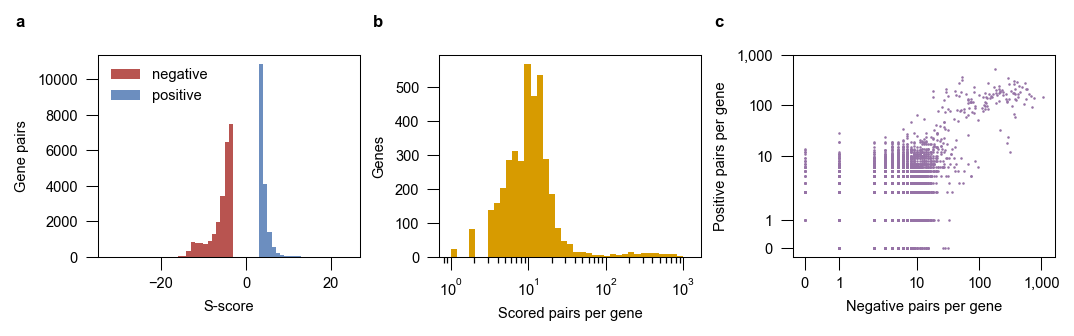

In [17]:
figure, (left, middle, right) = three_panels()
edges = np.arange(-32, 25, 1)
negative = pairs["s_score"] < 0
left.hist(pairs.loc[negative, "s_score"], bins=edges, color=NEGATIVE, label="negative")
left.hist(pairs.loc[~negative, "s_score"], bins=edges, color=POSITIVE, label="positive")
left.set(xlabel="S-score", ylabel="Gene pairs")
left.legend()

# One row per gene: how many of its pairs score below zero and how many above.
per_gene = (
    pd.concat(
        [
            pairs[["id_a", "s_score"]].rename(columns={"id_a": "id"}),
            pairs[["id_b", "s_score"]].rename(columns={"id_b": "id"}),
        ]
    )
    .assign(negative=lambda t: t["s_score"] < 0, positive=lambda t: t["s_score"] > 0)
    .groupby("id")[["negative", "positive"]]
    .sum()
)
degree = per_gene["negative"] + per_gene["positive"]
middle.hist(degree, bins=np.logspace(0, np.log10(degree.max() + 1), 40), color=ORANGE)
middle.set(xscale="log", xlabel="Scored pairs per gene", ylabel="Genes")

right.scatter(
    per_gene["negative"],
    per_gene["positive"],
    s=1.5,
    color=PURPLE,
    linewidths=0,
    rasterized=True,
)
right.set(
    xscale="symlog",
    yscale="symlog",
    xlabel="Negative pairs per gene",
    ylabel="Positive pairs per gene",
)
for axis in (right.xaxis, right.yaxis):  # linear from 0 to 1, logarithmic above
    axis.set_ticks([0, 1, 10, 100, 1000], labels=["0", "1", "10", "100", "1,000"])
    axis.minorticks_off()
save(figure, "gene_interaction_babu2014")

## Metabolome (Fuhrer 2017)

One record per Keio strain. The label maps each detected ion to a modified z-score. An ion is a mass feature of the negative or the positive instrument mode, keyed `neg_0001`, `pos_0001` and so on, and `ions.csv` gives its mass-to-charge ratio.

In [18]:
metabolome = MetabolomeFuhrer2017Dataset(root=str(DATA / "metabolome_fuhrer2017"))
print(f"{len(metabolome):,} records")
record = metabolome[0]
levels = record["experiment"]["phenotype"]["metabolite_level"]  # ion key -> z-score
print("strain", record["experiment"]["genotype"]["perturbations"][0]["strain_label"])
print("ions", len(levels), "first", dict(list(levels.items())[:4]))
ions = pd.read_csv(Path(metabolome.preprocess_dir) / "ions.csv")  # ion key -> m/z
# The ions are mass features of the two instrument modes, not named metabolites.
print(ions.groupby("mode")["deposit_mz"].agg(["size", "min", "max"]).to_string())
ions.head(4)

3,806 records
strain aaeA
ions 7534 first {'neg_0001': -0.4309, 'neg_0002': -0.1195, 'neg_0003': -0.6621, 'neg_0004': 0.9284}
      size      min       max
mode                         
neg   3169  56.9972  998.7170
pos   4365  55.0177  998.7871


,key,mode,ion_index,deposit_mz,table_ev1b_mz
0,neg_0001,neg,1,56.9972,56.9962
1,neg_0002,neg,2,57.0358,57.0348
2,neg_0003,neg,3,57.0574,57.0565
3,neg_0004,neg,4,58.0390,58.0380


In [19]:
ion_keys = list(levels)
strains, matrix_rows = [], []
for r in (metabolome[i] for i in range(len(metabolome))):
    perturbations = r["experiment"]["genotype"]["perturbations"]
    strains.append("+".join(p["perturbed_gene_name"] for p in perturbations))
    row_levels = r["experiment"]["phenotype"]["metabolite_level"]
    matrix_rows.append([row_levels[key] for key in ion_keys])
matrix = np.asarray(matrix_rows, dtype=np.float32)  # strains x ions
print("matrix shape", matrix.shape, matrix.dtype)
print("z-scores beyond 5 in absolute value:", int((np.abs(matrix) > 5).sum()))
print("records that name more than one gene:", sum("+" in name for name in strains))
pd.DataFrame(matrix[:5, :5], index=strains[:5], columns=ion_keys[:5])

matrix shape (3806, 7534) float32
z-scores beyond 5 in absolute value: 31863
records that name more than one gene: 21


,neg_0001,neg_0002,neg_0003,neg_0004,neg_0005
aaeA,-0.4309,-0.1195,-0.6621,0.9284,-0.6906
aaeB,-1.8696,1.1863,1.7171,0.3849,0.7550
aaeR,1.3402,-0.8219,1.0256,2.0786,-0.5455
aaeX,0.2608,-0.5211,0.0221,-0.8930,0.4659
aas,1.1950,0.2000,-0.4579,0.8433,0.5156


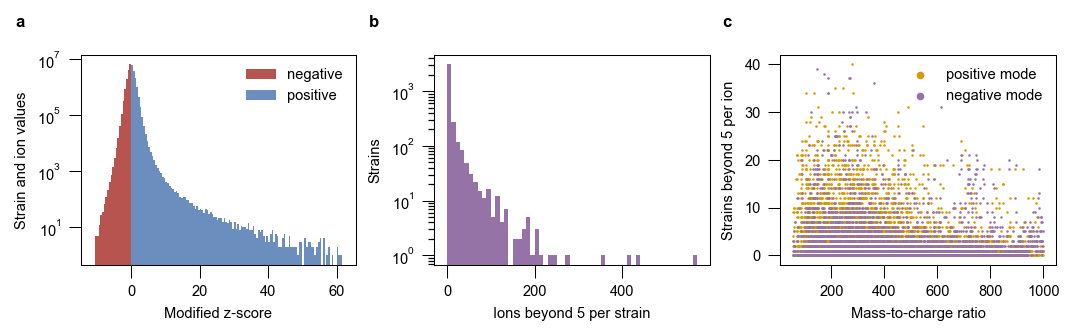

In [20]:
figure, (left, middle, right) = three_panels()
values = matrix.ravel()
edges = np.arange(-11.0, 62.5, 0.5)
left.hist(values[values < 0], bins=edges, color=NEGATIVE, label="negative")
left.hist(values[values >= 0], bins=edges, color=POSITIVE, label="positive")
left.set(yscale="log", xlabel="Modified z-score", ylabel="Strain and ion values")
left.legend()

beyond = np.abs(matrix) > 5
middle.hist(beyond.sum(axis=1), bins=np.arange(0, 580, 10), color=PURPLE)
middle.set(yscale="log", xlabel="Ions beyond 5 per strain", ylabel="Strains")

# Ionization mode is a property of the instrument run, not a sign of the value.
for mode, color in (("pos", ORANGE), ("neg", PURPLE)):
    of_mode = (ions["mode"] == mode).to_numpy()
    right.scatter(
        ions.loc[of_mode, "deposit_mz"],
        beyond.sum(axis=0)[of_mode],
        s=1.5,
        color=color,
        linewidths=0,
        rasterized=True,
        label={"neg": "negative mode", "pos": "positive mode"}[mode],
    )
right.set(xlabel="Mass-to-charge ratio", ylabel="Strains beyond 5 per ion")
right.legend(markerscale=3, loc="upper right")
save(figure, "metabolome_fuhrer2017")

## How each dataset names its genes

Every perturbation carries the gene symbol (`perturbed_gene_name`) and an identifier (`systematic_gene_name`) in the namespace `gene_namespace` names. The identifier differs by dataset, and the table says which kind each one stores and what it was mapped from.

In [21]:
loaded = {
    "ecoli_growth_rate_campos2018": growth,
    "ecoli_morphology_campos2018": morphology,
    "gene_interaction_babu2014": interaction,
    "metabolome_fuhrer2017": metabolome,
}
# Every perturbation names its gene twice: perturbed_gene_name is the gene symbol and
# systematic_gene_name is the identifier in the namespace gene_namespace names.
rows = []
for slug, dataset in loaded.items():
    for r in (dataset[i] for i in range(len(dataset))):
        for p in r["experiment"]["genotype"]["perturbations"]:
            mapping = p["identifier_mapping"] or {}
            rows.append(
                {
                    "dataset": slug,
                    "symbol": p["perturbed_gene_name"],
                    "identifier": p["systematic_gene_name"],
                    "namespace": p["gene_namespace"],
                    "identifier_kind": p.get("identifier_kind") or "locus identifier",
                    "mapped_from": mapping.get("route") or "released as is",
                    "perturbation_type": p["perturbation_type"],
                }
            )
names = pd.DataFrame(rows)
how = ["dataset", "perturbation_type", "namespace", "identifier_kind", "mapped_from"]
gene_names = (
    names.groupby(how, sort=False)
    .agg(
        perturbations=("symbol", "size"),
        genes=("identifier", "nunique"),
        example_symbol=("symbol", "first"),
        example_identifier=("identifier", "first"),
    )
    .reset_index()
)
print(gene_names.to_string(index=False))
gene_names

                     dataset   perturbation_type                   namespace                 identifier_kind    mapped_from  perturbations  genes example_symbol example_identifier
ecoli_growth_rate_campos2018     deletion_strain ecoli_k12_bw25113_locus_tag                locus identifier    gene_symbol           3664   3664           hchA       BW25113_1967
 ecoli_morphology_campos2018     deletion_strain ecoli_k12_bw25113_locus_tag                locus identifier    gene_symbol           3664   3664           hchA       BW25113_1967
   gene_interaction_babu2014     deletion_strain    ecoli_k12_mg1655_bnumber                locus identifier released as is          81777   3719           thrA              b0002
   gene_interaction_babu2014       marked_allele    ecoli_k12_mg1655_bnumber                locus identifier released as is           3503    150           holA              b0640
   gene_interaction_babu2014 released_identifier    ecoli_k12_mg1655_bnumber b-number with a Keio su

,dataset,perturbation_type,namespace,identifier_kind,mapped_from,perturbations,genes,example_symbol,example_identifier
0,ecoli_growth_rate_campos2018,deletion_strain,ecoli_k12_bw25113_locus_tag,locus identifier,gene_symbol,3664,3664,hchA,BW25113_1967
1,ecoli_morphology_campos2018,deletion_strain,ecoli_k12_bw25113_locus_tag,locus identifier,gene_symbol,3664,3664,hchA,BW25113_1967
2,gene_interaction_babu2014,deletion_strain,ecoli_k12_mg1655_bnumber,locus identifier,released as is,81777,3719,thrA,b0002
3,gene_interaction_babu2014,marked_allele,ecoli_k12_mg1655_bnumber,locus identifier,released as is,3503,150,holA,b0640
4,gene_interaction_babu2014,released_identifier,ecoli_k12_mg1655_bnumber,b-number with a Keio sub-number,released as is,93,8,yaaV,b0033.1
5,gene_interaction_babu2014,released_identifier,ecoli_k12_mg1655_bnumber,Keio JW number,released as is,33,2,fucT,JW5447
6,gene_interaction_babu2014,released_identifier,ecoli_k12_mg1655_bnumber,gene symbol,released as is,4,1,xylU,cscR
7,metabolome_fuhrer2017,released_identifier,ecoli_k12_bw25113_locus_tag,Keio JW id,released as is,3830,3830,aaeA,JW3210


## At a glance

The same rows for every dataset, counted from the loaded records: the shape of the labels, the genotype and how it was perturbed, and the growth condition.

In [22]:
# The same rows for every dataset, counted from the loaded records: the shape of the
# labels, what the genotype is and how it was perturbed, and the growth condition.


def plain(value: Any) -> str:
    """A field as text; an enum shows its value."""
    return str(getattr(value, "value", value))


def tally(values: list[Any]) -> str:
    """The distinct values, most frequent first, with counts when there are several."""
    counts = pd.Series([plain(v) for v in values]).value_counts()
    if len(counts) == 1:
        return str(counts.index[0])
    return "; ".join(f"{value} ({n:,})" for value, n in counts.items())


def glance(dataset: Any) -> dict[str, str]:
    """One dataset's row values, in the order every dataset is shown in."""
    experiments = [dataset[i]["experiment"] for i in range(len(dataset))]
    perturbations = [p for e in experiments for p in e["genotype"]["perturbations"]]
    phenotypes = [e["phenotype"] for e in experiments]
    labels = [ph[ph["label_name"]] for ph in phenotypes]
    values = [x for v in labels for x in (v.values() if isinstance(v, dict) else [v])]
    width = max(len(v) if isinstance(v, dict) else 1 for v in labels)
    cells = len(experiments) * width  # a record may lack some of the label's values
    missing = cells - sum(x is not None and x == x for x in values)
    samples = [ph["n_samples"] for ph in phenotypes if ph.get("n_samples") is not None]
    media = [e["environment"]["media"] for e in experiments]
    # A strain is a genotype: the set of perturbed genes, each with how it was perturbed.
    strains = {
        tuple(
            sorted(
                (p["systematic_gene_name"], p["perturbation_type"])
                for p in e["genotype"]["perturbations"]
            )
        )
        for e in experiments
    }
    return {
        "Records": f"{len(experiments):,}",
        "Distinct strains (genotypes)": f"{len(strains):,}",
        "Label array (records x values)": f"{len(experiments):,} x {width:,}",
        "Missing label values": f"{missing:,} of {cells:,}",
        "Experiment type": tally([e["experiment_type"] for e in experiments]),
        "Label field": tally([ph["label_name"] for ph in phenotypes]),
        "Label attaches to": tally([ph["graph_level"] for ph in phenotypes]),
        "Measurements behind one record": (
            (
                f"{min(samples):,}"
                if min(samples) == max(samples)
                else f"{min(samples):,} to {max(samples):,}"
            )
            + " "
            + tally([ph.get("sample_unit") for ph in phenotypes])
            if samples
            else "not recorded"
        ),
        "Genes perturbed per record": tally(
            [len(e["genotype"]["perturbations"]) for e in experiments]
        ),
        "Perturbation type": tally([p["perturbation_type"] for p in perturbations]),
        "Perturbation mechanism": tally(
            [
                p.get("mechanism_so_name") or p.get("released_kind")
                for p in perturbations
            ]
        ),
        "Strain collection": tally([p.get("collection") for p in perturbations]),
        "Distinct genes perturbed": f"{len({p['perturbed_gene_name'] for p in perturbations}):,}",
        "Gene identifier namespace": tally(
            [p["gene_namespace"] for p in perturbations]
        ),
        "Medium": tally([f"{m['base_medium']}, {m['state']}" for m in media]),
        "Temperature": tally(
            [
                f"{e['environment']['temperature']['value']:g} "
                f"{plain(e['environment']['temperature']['unit'])}"
                for e in experiments
            ]
        ),
    }


at_a_glance = pd.DataFrame({slug: glance(dataset) for slug, dataset in loaded.items()})
at_a_glance.index.name = "property"
for line in [
    " | ".join(["property", *at_a_glance.columns]),
    *(" | ".join([name, *row]) for name, row in at_a_glance.iterrows()),
]:
    print(line)
at_a_glance

property | ecoli_growth_rate_campos2018 | ecoli_morphology_campos2018 | gene_interaction_babu2014 | metabolome_fuhrer2017
Records | 3,664 | 3,664 | 42,705 | 3,806
Distinct strains (genotypes) | 3,664 | 3,664 | 42,603 | 3,806
Label array (records x values) | 3,664 x 1 | 3,664 x 15 | 42,705 x 1 | 3,806 x 7,534
Missing label values | 0 of 3,664 | 1,452 of 54,960 | 0 of 42,705 | 0 of 28,674,404
Experiment type | fitness | morphology | gene interaction | metabolite
Label field | fitness | morphology | gene_interaction | metabolite_level
Label attaches to | global | global | hyperedge | metabolism
Measurements behind one record | 1 biological_replicate | 43 to 1,658 cell | 8 colony | not recorded
Genes perturbed per record | 1 | 1 | 2 | 1 (3,785); 2 (18); 3 (3)
Perturbation type | deletion_strain | deletion_strain | deletion_strain (81,777); marked_allele (3,503); released_identifier (130) | released_identifier
Perturbation mechanism | deletion | deletion | deletion (81,907); transgenic_inse

,ecoli_growth_rate_campos2018,ecoli_morphology_campos2018,gene_interaction_babu2014,metabolome_fuhrer2017
property,,,,
Records,"3,664","3,664","42,705","3,806"
Distinct strains (genotypes),"3,664","3,664","42,603","3,806"
Label array (records x values),"3,664 x 1","3,664 x 15","42,705 x 1","3,806 x 7,534"
Missing label values,"0 of 3,664","1,452 of 54,960","0 of 42,705","0 of 28,674,404"
Experiment type,fitness,morphology,gene interaction,metabolite
Label field,fitness,morphology,gene_interaction,metabolite_level
Label attaches to,global,global,hyperedge,metabolism
Measurements behind one record,1 biological_replicate,"43 to 1,658 cell",8 colony,not recorded
Genes perturbed per record,1,1,2,"1 (3,785); 2 (18); 3 (3)"


Gene symbols shared by each pair of datasets (the diagonal is the dataset's own count).

In [23]:
# The gene symbol is the name every dataset carries, so it is the key to join on.
symbols = {slug: set(group["symbol"]) for slug, group in names.groupby("dataset")}
overlap = pd.DataFrame(
    {a: {b: len(symbols[a] & symbols[b]) for b in loaded} for a in loaded}
)
print(overlap.to_string())
overlap

                              ecoli_growth_rate_campos2018  ecoli_morphology_campos2018  gene_interaction_babu2014  metabolome_fuhrer2017
ecoli_growth_rate_campos2018                          3664                         3664                       3176                   3154
ecoli_morphology_campos2018                           3664                         3664                       3176                   3154
gene_interaction_babu2014                             3176                         3176                       3876                   3510
metabolome_fuhrer2017                                 3154                         3154                       3510                   3806


,ecoli_growth_rate_campos2018,ecoli_morphology_campos2018,gene_interaction_babu2014,metabolome_fuhrer2017
ecoli_growth_rate_campos2018,3664,3664,3176,3154
ecoli_morphology_campos2018,3664,3664,3176,3154
gene_interaction_babu2014,3176,3176,3876,3510
metabolome_fuhrer2017,3154,3154,3510,3806


## Check the records against the release

Hashing the loaded records reproduces the content hash the knowledge-graph release recorded.

In [24]:
def experiment_id(record: dict[str, Any]) -> str:
    """The id the knowledge graph gives this record: sha256 of its experiment."""
    return hashlib.sha256(json.dumps(record["experiment"]).encode("utf-8")).hexdigest()


for slug, dataset in loaded.items():
    ids = (experiment_id(dataset[i]) for i in range(len(dataset)))
    digest = content_sha256(ids)  # one hash over every record of the dataset
    served = client.select(slug).content_sha256  # what the release recorded
    print(
        f"{slug}  {digest}  {'matches' if digest == served else 'DIFFERS FROM'} the release"
    )

ecoli_growth_rate_campos2018  a8ced65c7e68b1d673ad404f001dc47fb9807db7cc3b131282bf532d10f7e11c  matches the release
ecoli_morphology_campos2018  15d7c23e9300015d48426f8b7e813aec540bd5a9854e8392b7ab1eef19836e6b  matches the release
gene_interaction_babu2014  fb1f87b2c861a2df6e06bfe8abdcb71bbd46ff77fe56ba2c53996a65f2584f10  matches the release
metabolome_fuhrer2017  adeb2d85353f426d3a775eab4c09e99e97c47b9c3b96be6684c54cfa6d2162bd  matches the release
